In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,    roc_auc_score

)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score


In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Data Shape:", df.shape)

Data Shape: (7043, 21)


In [5]:
print("Columns:", df.columns)

print("\n Data Information:")
df.info()

print("\nMissing Values: ")
print(df.isna().sum())

Columns: Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

 Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043

In [6]:
print("\nDuplicates Rows:", df.duplicated().sum())


Duplicates Rows: 0


In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors = "coerce"
)

In [8]:
print("\nMissing a valuues after a conversion: ", df.isnull().sum())


Missing a valuues after a conversion:  customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [9]:
df = df.dropna(subset = ["TotalCharges"])

df = df.drop_duplicates()

print("\n Data shape after filling", df.shape)

df.info()


 Data shape after filling (7032, 21)
<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   str    
 1   gender            7032 non-null   str    
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   str    
 4   Dependents        7032 non-null   str    
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   str    
 7   MultipleLines     7032 non-null   str    
 8   InternetService   7032 non-null   str    
 9   OnlineSecurity    7032 non-null   str    
 10  OnlineBackup      7032 non-null   str    
 11  DeviceProtection  7032 non-null   str    
 12  TechSupport       7032 non-null   str    
 13  StreamingTV       7032 non-null   str    
 14  StreamingMovies   7032 non-null   str    
 15  Contract          7032 non-null   str    
 16  PaperlessBilling  70

In [10]:
print(df["Churn"].value_counts())

print("\n Churn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5163
Yes    1869
Name: count, dtype: int64

 Churn Percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


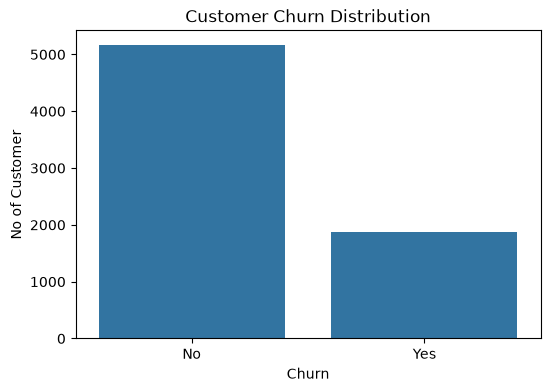

In [11]:
plt.figure(figsize = (6,4))
sns.countplot(data = df, x = "Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("No of Customer")

plt.show()

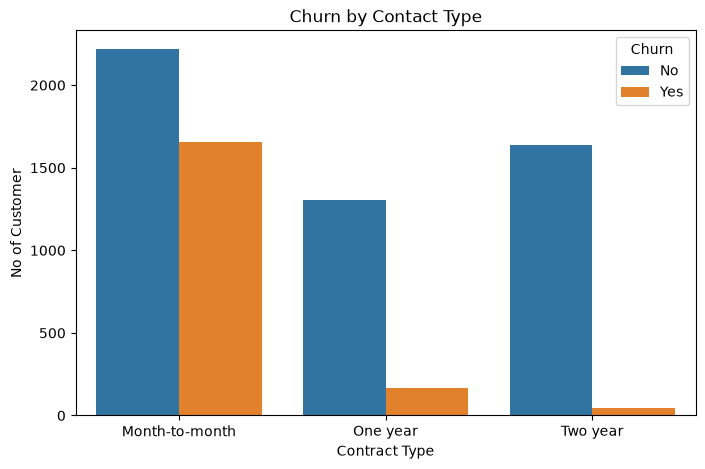

In [12]:
#Churn vs Contract
plt.figure(figsize = (8,5))
sns.countplot(data = df, x="Contract", hue= "Churn")

plt.title("Churn by Contact Type")
plt.xlabel("Contract Type")
plt.ylabel("No of Customer")
plt.show()

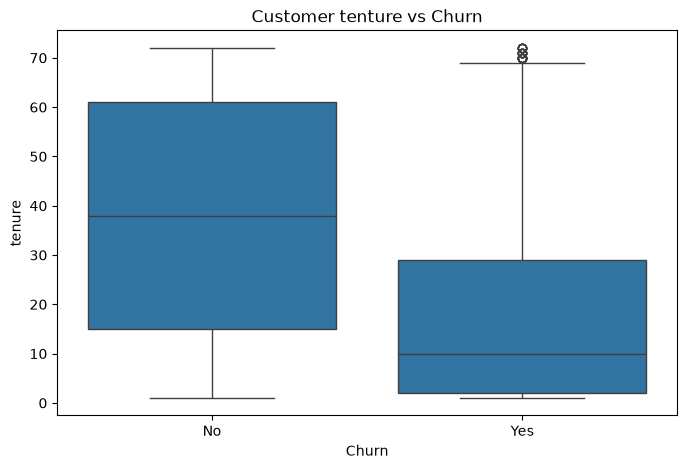

In [13]:
plt.figure(figsize = (8,5))
sns.boxplot(data = df, x = "Churn", y="tenure")

plt.title("Customer tenture vs Churn")
plt.show()

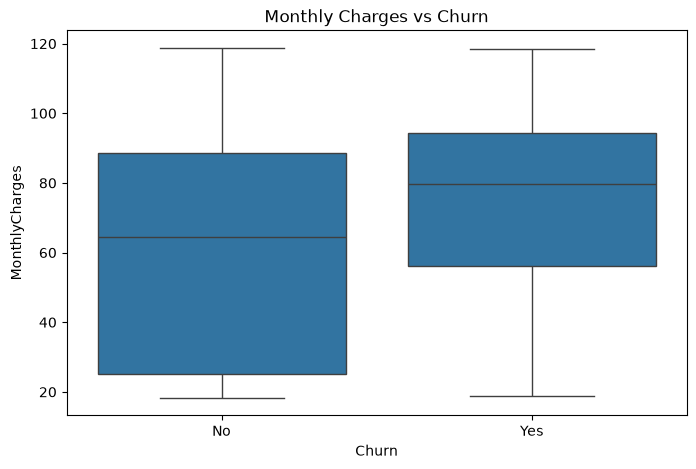

In [14]:
plt.figure(figsize = (8,5))
sns.boxplot(data = df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.show()

**Preparing Data for Machine Learning**

In [15]:
# Remove customerID because it does not help prediction
X = df.drop(columns=["Churn", "customerID"])

#Target varables
y = df["Churn"].map({"No" : 0,
                     "Yes" : 1
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\n Target values:")
print(y.value_counts())


Features Shape: (7032, 19)
Target Shape: (7032,)

 Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [16]:
#**Train and Testing Splitting**

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state =42,
    stratify = y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution :")
print(y_train.value_counts(normalize= True) * 100)

print("\nTestinging Target Distribution :")
print(y_test.value_counts(normalize= True) * 100)

Training Data: (5625, 19)
Testing Data: (1407, 19)

Training Target Distribution :
Churn
0    73.422222
1    26.577778
Name: proportion, dtype: float64

Testinging Target Distribution :
Churn
0    73.418621
1    26.581379
Name: proportion, dtype: float64


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Select columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns

# Numerical pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Create preprocessor
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Training
X_train_processed = preprocessor.fit_transform(X_train)

# Testing
X_test_processed = preprocessor.transform(X_test)

print("Training Processed Shape:", X_train_processed.shape)
print("Testing Processed Shape:", X_test_processed.shape)

Training Processed Shape: (5625, 45)
Testing Processed Shape: (1407, 45)


**Model Using a Logistic Regressionn**

In [26]:
model = LogisticRegression(max_iter = 1000)

model.fit(X_train_processed, y_train)

print("Model Training Completed")

Model Training Completed


Prediction

In [27]:
y_pred = model.predict(X_test_processed)

print("First 20 Prediction:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test.iloc[:20].values)

First 20 Prediction:
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]

Actual Values:
[0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 0]


Model evaluation
\n Accuracy, confusion matrix, classification report

In [30]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 80.38379530916845 %

Confusion Matrix:
[[917 116]
 [160 214]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



**Decision Tree***10

In [32]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train model
dt_model.fit(X_train_processed, y_train)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


In [33]:
dt_pred = dt_model.predict(X_test_processed)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred) * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 73.0632551528074 %

Confusion Matrix:
[[842 191]
 [188 186]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82      1033
           1       0.49      0.50      0.50       374

    accuracy                           0.73      1407
   macro avg       0.66      0.66      0.66      1407
weighted avg       0.73      0.73      0.73      1407



In [35]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred)
    ],
    "Churn Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred)
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred)
    ],
    "Churn F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred)
    ]
})

print(comparison)

                 Model  Accuracy  Churn Precision  Churn Recall  \
0  Logistic Regression  0.803838         0.648485      0.572193   
1        Decision Tree  0.730633         0.493369      0.497326   

   Churn F1 Score  
0        0.607955  
1        0.495340  


**Improve Churn Recall**

In [36]:
# Create balanced model
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train model
balanced_model.fit(X_train_processed, y_train)

# Predict
balanced_pred = balanced_model.predict(X_test_processed)

print("Balanced Logistic Regression Training Completed!")

Balanced Logistic Regression Training Completed!


In [37]:
print("Accuracy:",
      accuracy_score(y_test, balanced_pred) * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))

print("\nClassification Report:")
print(classification_report(y_test, balanced_pred))

Accuracy: 72.56574271499645 %

Confusion Matrix:
[[723 310]
 [ 76 298]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [38]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, balanced_pred)
    ],
    "Churn Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, balanced_pred)
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, balanced_pred)
    ],
    "Churn F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, balanced_pred)
    ]
})

print(comparison.round(3))

                          Model  Accuracy  Churn Precision  Churn Recall  \
0           Logistic Regression     0.804            0.648         0.572   
1                 Decision Tree     0.731            0.493         0.497   
2  Balanced Logistic Regression     0.726            0.490         0.797   

   Churn F1 Score  
0           0.608  
1           0.495  
2           0.607  


**Threshold**

In [39]:
# Split training data into sub-training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create complete ML pipeline
threshold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train
threshold_model.fit(X_subtrain, y_subtrain)

# Get churn probabilities
y_val_prob = threshold_model.predict_proba(X_val)[:, 1]

# Compare thresholds
results = []

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1 Score": f1_score(y_val, y_val_pred)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))

   Threshold  Precision  Recall  F1 Score
0        0.3      0.428   0.923     0.585
1        0.4      0.472   0.873     0.613
2        0.5      0.523   0.783     0.627
3        0.6      0.555   0.696     0.617


**Final MOdel Evaluation**


In [40]:
# Train on complete training dataset
threshold_model.fit(X_train, y_train)

# Predict probabilities on test data
test_probabilities = threshold_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
final_pred = (test_probabilities >= 0.5).astype(int)

print("Final Model Training Completed!")

Final Model Training Completed!


In [42]:
print("Final Model Accuracy:",
      accuracy_score(y_test, final_pred) * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

print("\nClassification Report:")
print(classification_report(y_test, final_pred))

print("ROC-AUC Score:",
      roc_auc_score(y_test, test_probabilities))

Final Model Accuracy: 72.56574271499645 %

Confusion Matrix:
[[723 310]
 [ 76 298]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

ROC-AUC Score: 0.8351344145860403


In [43]:
import joblib

joblib.dump(threshold_model, "customer_churn_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!
